In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier
cr = pd.read_csv("/content/Crop_Recommendation.csv")
cr.head()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall,Crop
0,90,42,43,20.879744,82.002744,6.502985,202.935536,Rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,Rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,Rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,Rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,Rice


In [ ]:
cr.describe()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [ ]:
cr.head()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall,Crop
0,90,42,43,20.879744,82.002744,6.502985,202.935536,Rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,Rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,Rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,Rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,Rice


In [ ]:
cr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Nitrogen     2200 non-null   int64  
 1   Phosphorus   2200 non-null   int64  
 2   Potassium    2200 non-null   int64  
 3   Temperature  2200 non-null   float64
 4   Humidity     2200 non-null   float64
 5   pH_Value     2200 non-null   float64
 6   Rainfall     2200 non-null   float64
 7   Crop         2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [ ]:
cr.isnull().sum()

,0
Nitrogen,0
Phosphorus,0
Potassium,0
Temperature,0
Humidity,0
pH_Value,0
Rainfall,0
Crop,0


In [ ]:
feature_columns = ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'pH_Value', 'Rainfall']
X = cr[feature_columns]

scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)

df_normalized = pd.DataFrame(X_normalized, columns=feature_columns)

df_normalized['Crop'] = cr['Crop']

df_normalized.head()

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall,Crop
0,0.642857,0.264286,0.190,0.345886,0.790267,0.466264,0.656458,Rice
1,0.607143,0.378571,0.180,0.371445,0.770633,0.549480,0.741675,Rice
2,0.428571,0.357143,0.195,0.406854,0.793977,0.674219,0.875710,Rice
3,0.528571,0.214286,0.175,0.506901,0.768751,0.540508,0.799905,Rice
4,0.557143,0.264286,0.185,0.324378,0.785626,0.641291,0.871231,Rice


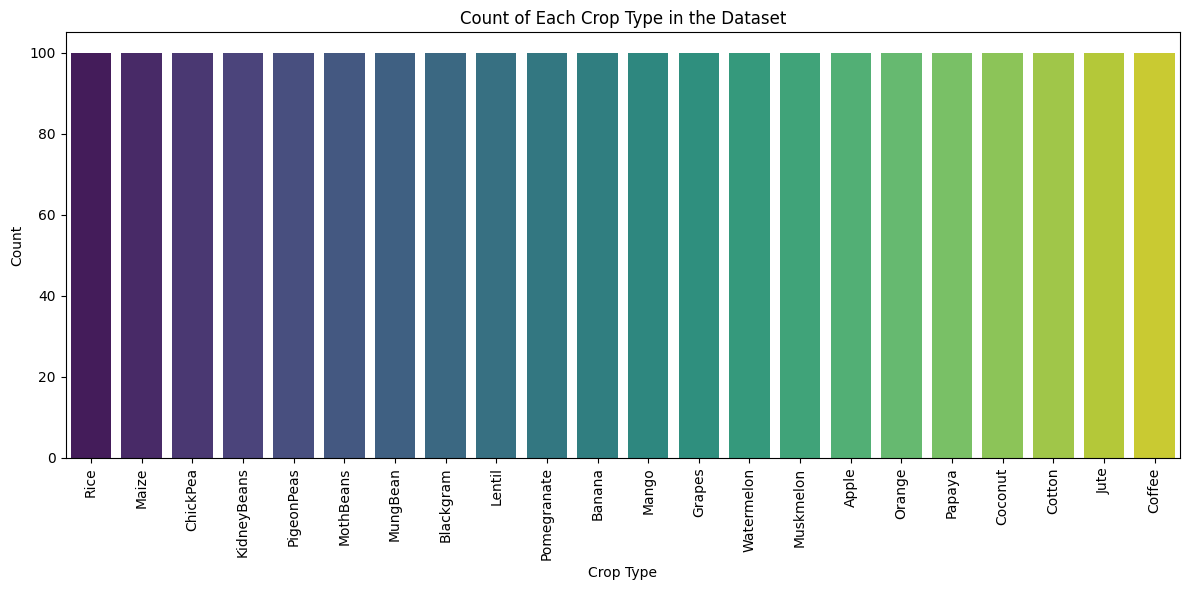

In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Crop', data=cr, palette='viridis', hue='Crop', legend=False)
plt.title('Count of Each Crop Type in the Dataset')
plt.xlabel('Crop Type')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

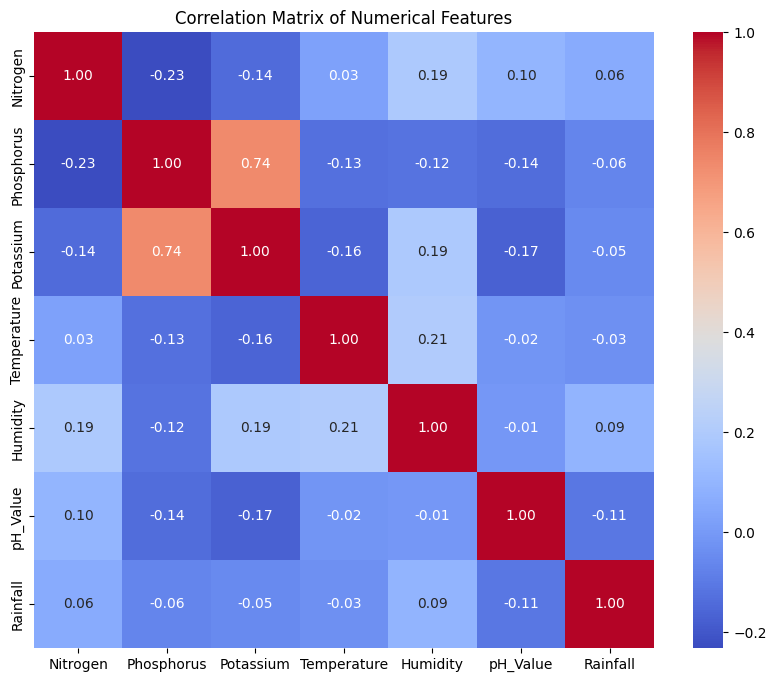

In [ ]:
#  hitmap
numerical_features = ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'pH_Value', 'Rainfall']

plt.figure(figsize=(10, 8))
correlation_matrix = cr[numerical_features].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

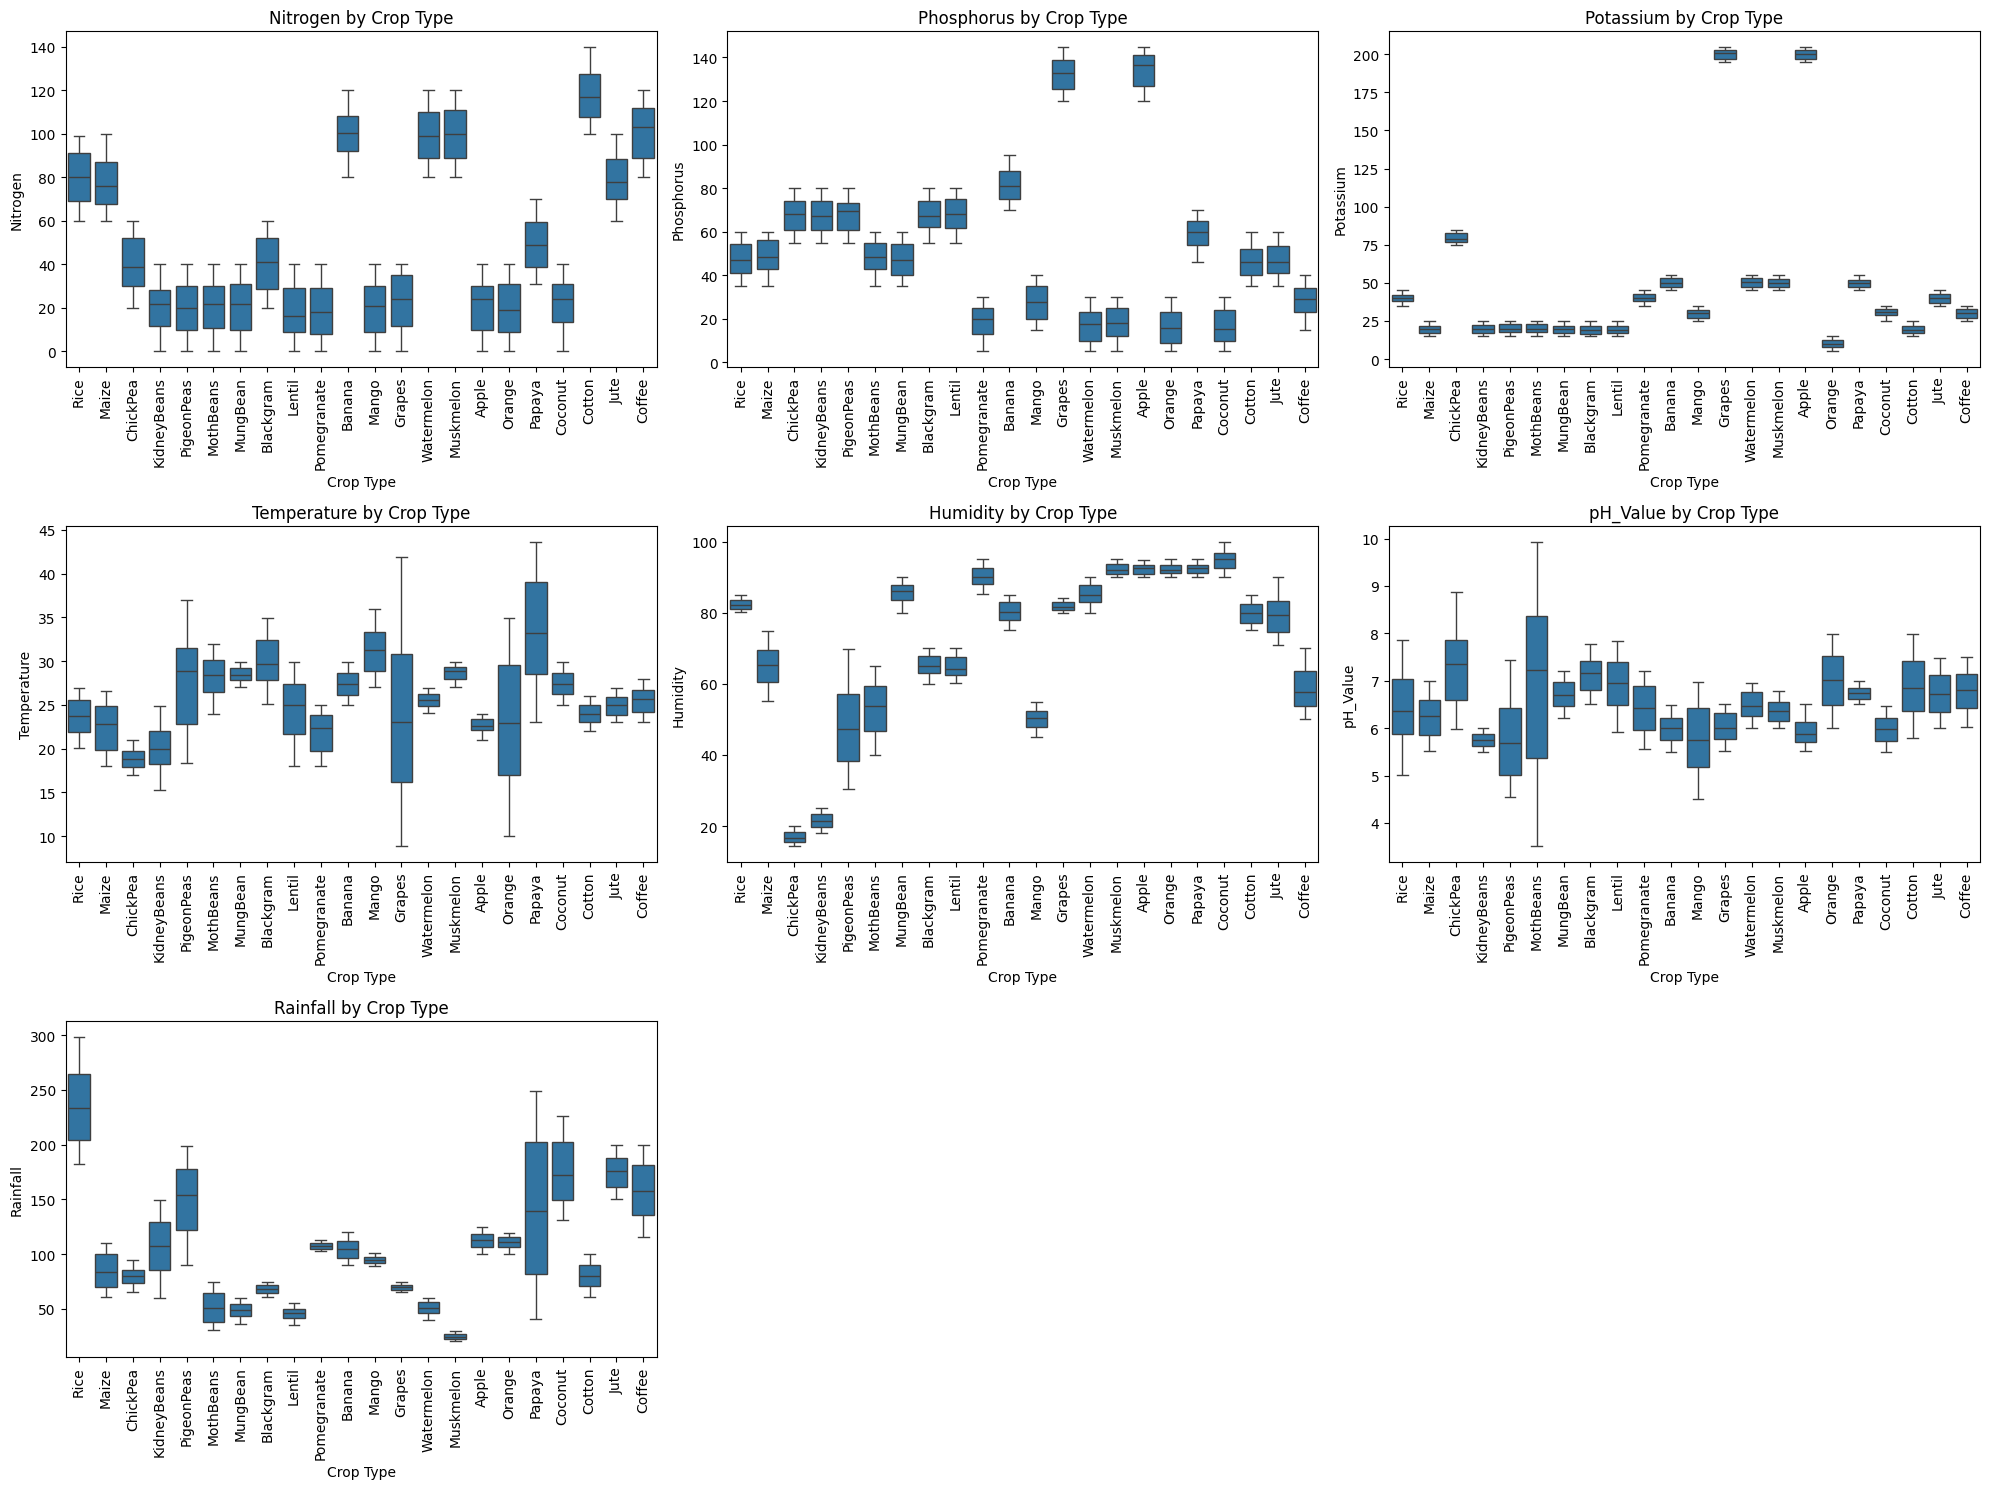

In [ ]:
# box plot
numerical_features = ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'pH_Value', 'Rainfall']

plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_features):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(x='Crop', y=col, data=cr)
    plt.title(f'{col} by Crop Type')
    plt.xlabel('Crop Type')
    plt.ylabel(col)
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

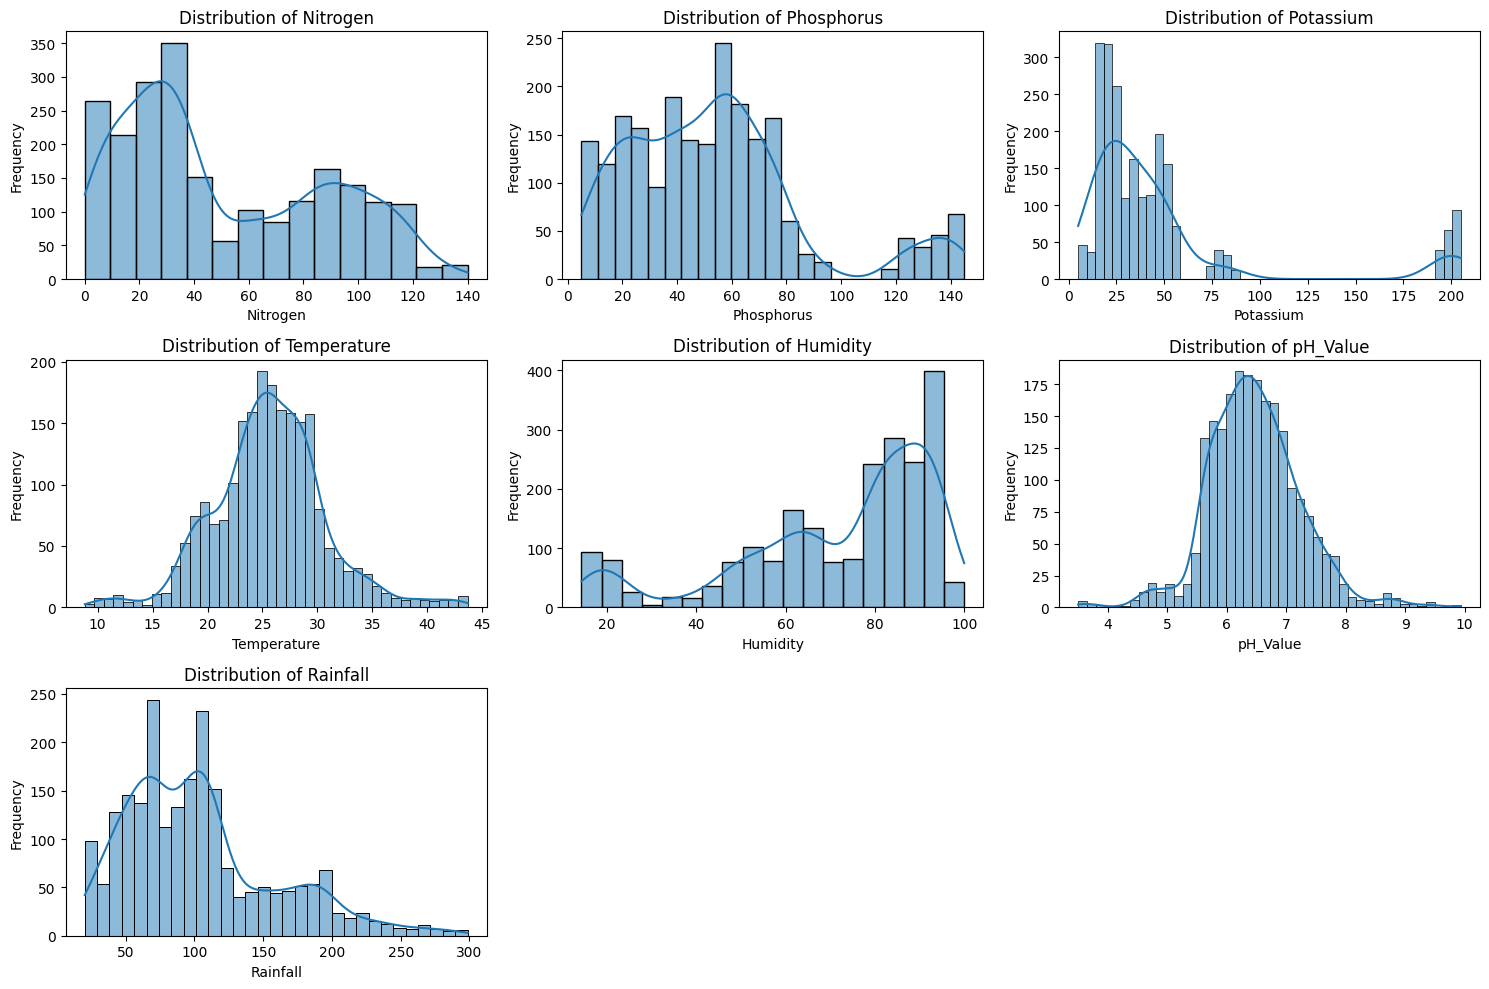

In [ ]:
# histogram
numerical_features = ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'pH_Value', 'Rainfall']

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_features):
    plt.subplot(3, 3, i + 1)
    sns.histplot(cr[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


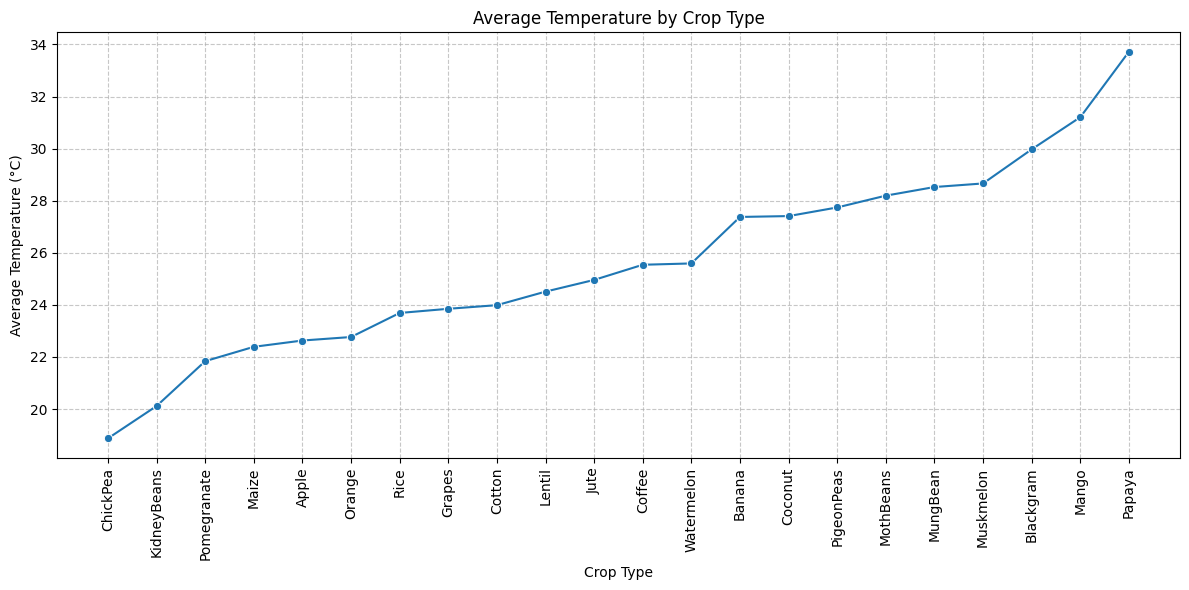

In [ ]:
#  line plot
mean_temp_by_crop = cr.groupby('Crop')['Temperature'].mean().sort_values()

plt.figure(figsize=(12, 6))
sns.lineplot(x=mean_temp_by_crop.index, y=mean_temp_by_crop.values, marker='o')
plt.title('Average Temperature by Crop Type')
plt.xlabel('Crop Type')
plt.ylabel('Average Temperature (°C)')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

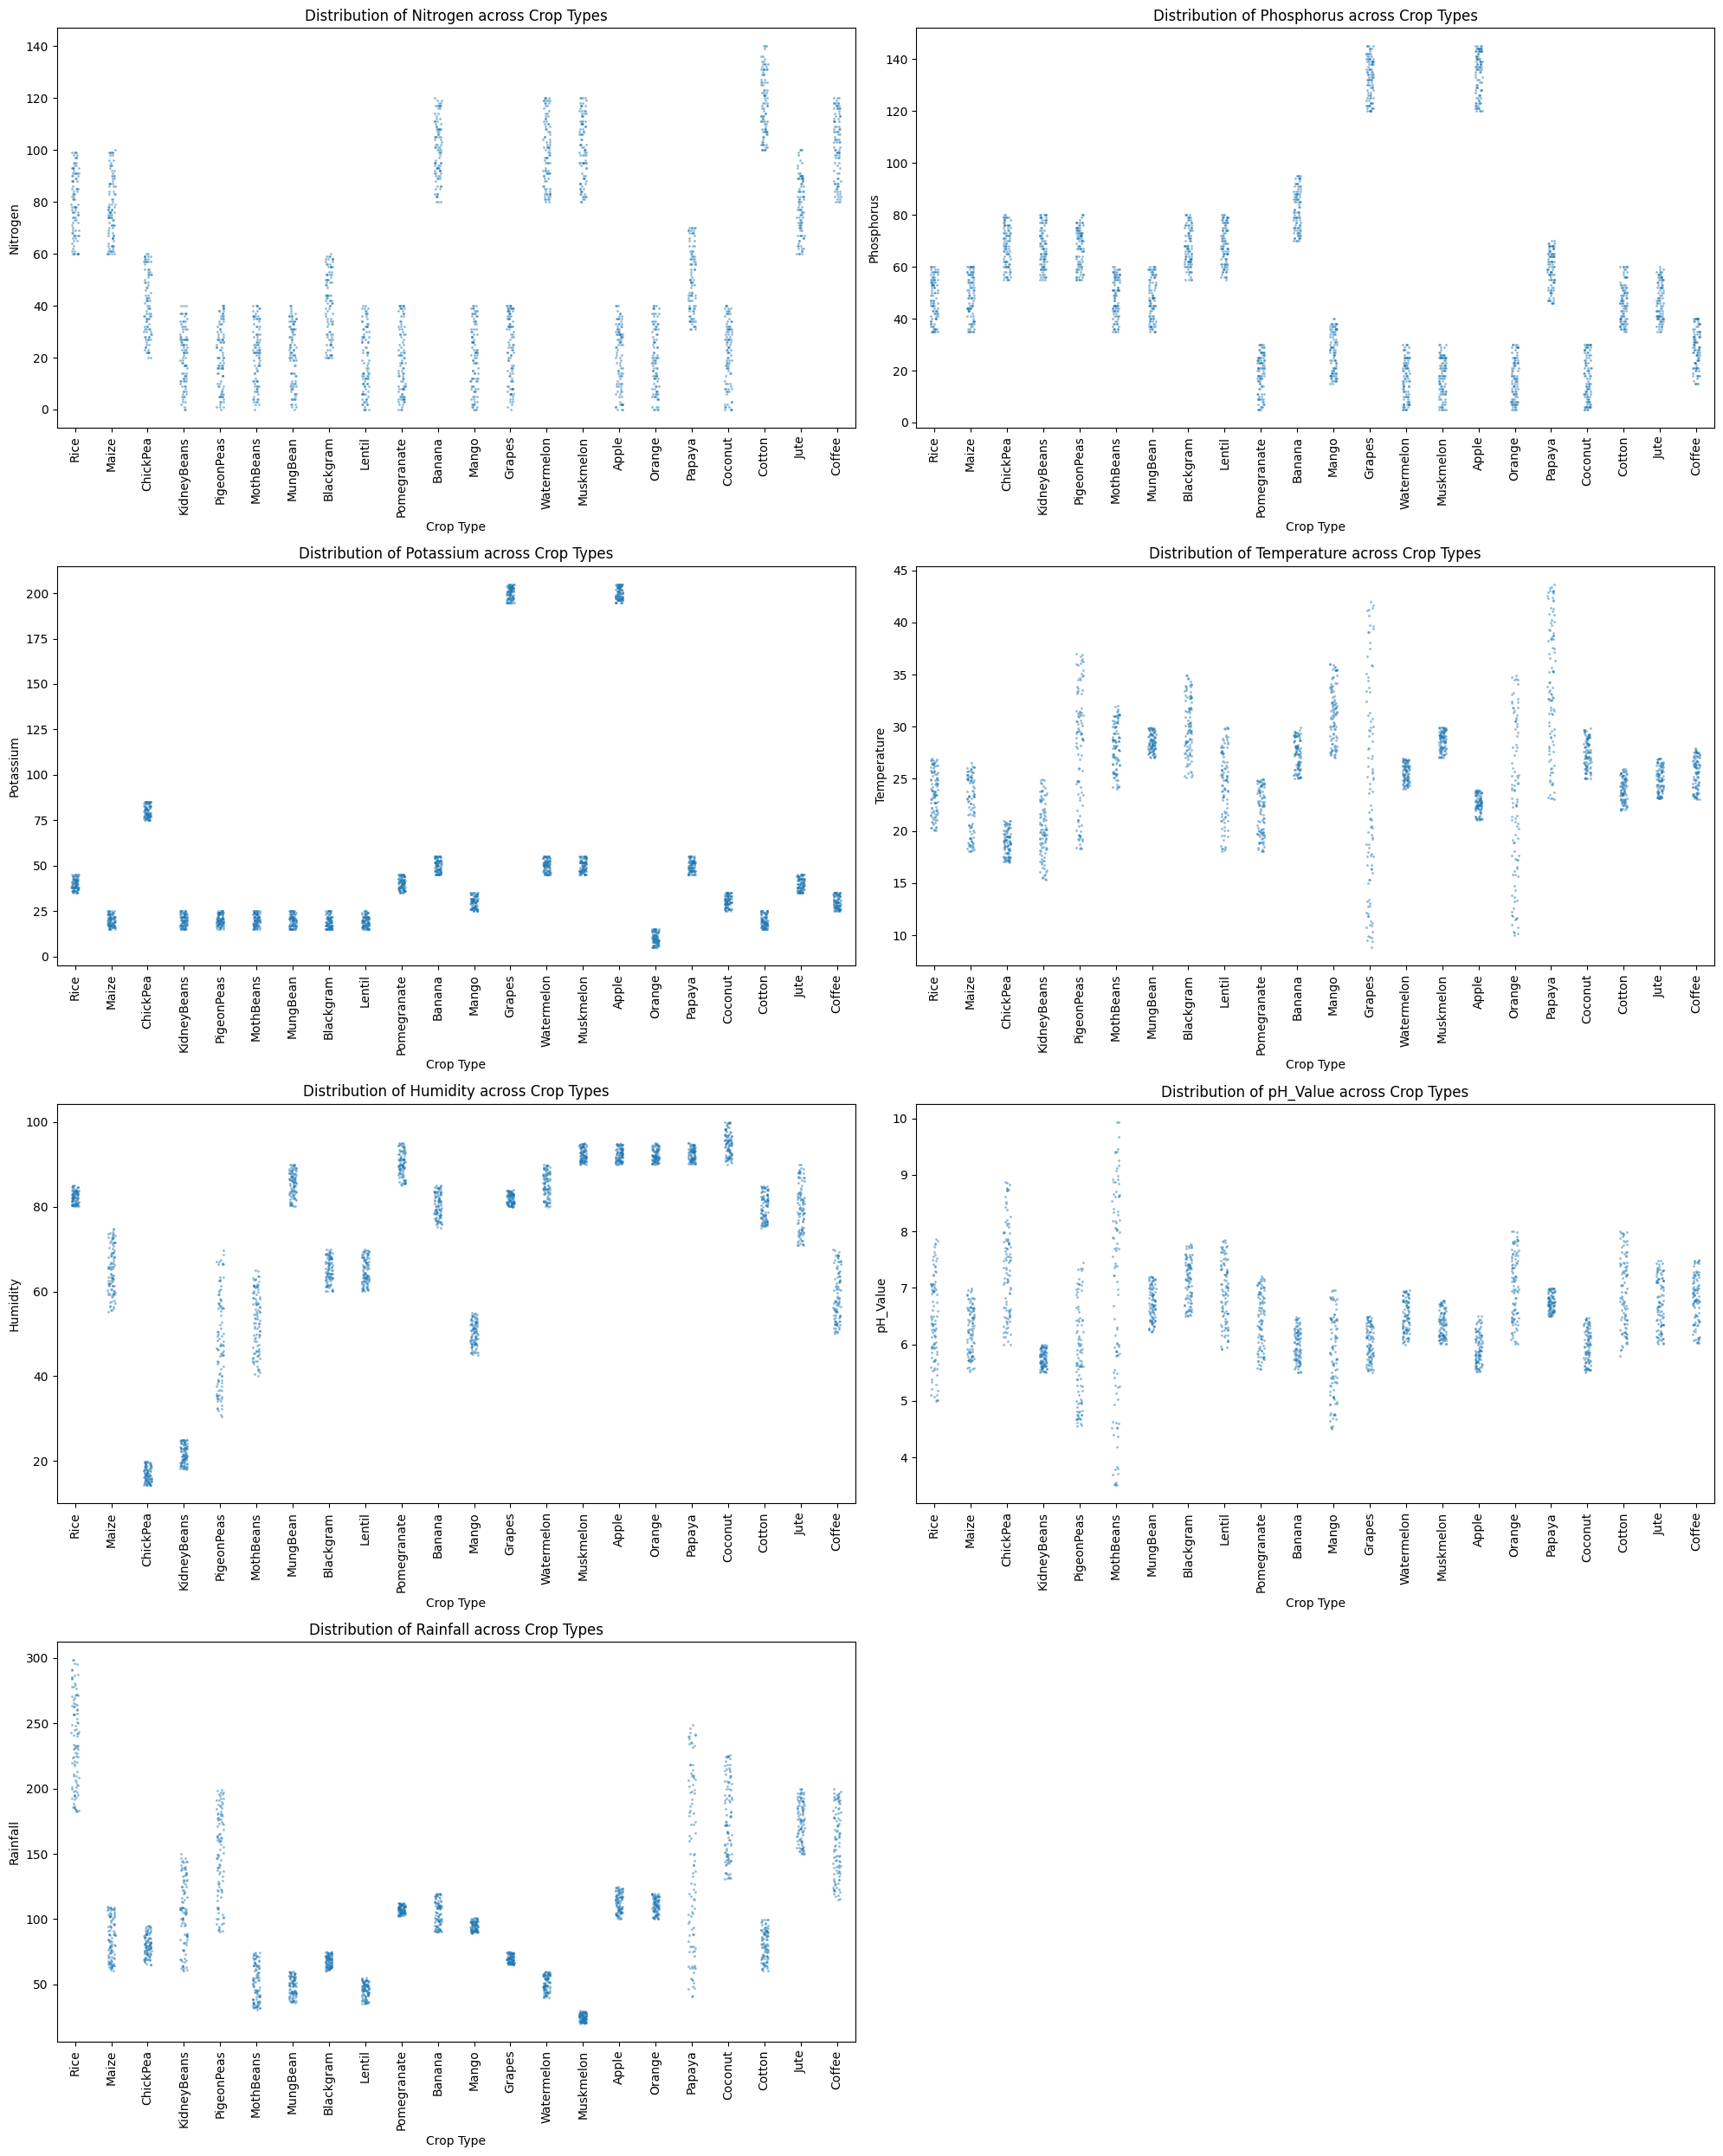

In [ ]:
# scatter plot using stripplot for better handling of dense data
numerical_cols = ['Nitrogen', 'Phosphorus', 'Potassium', 'Temperature', 'Humidity', 'pH_Value', 'Rainfall']
plt.figure(figsize=(20, 25))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 2, i + 1)
    sns.stripplot(x='Crop', y=col, data=cr, size=2, jitter=True, alpha=0.5)
    plt.title(f'Distribution of {col} across Crop Types')
    plt.xlabel('Crop Type')
    plt.ylabel(col)
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
X = cr.drop('Crop', axis=1)
y = cr['Crop']

# Encode labels to numerical values
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Scale features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Shape of X_train (training features): {X_train.shape}")
print(f"Shape of X_test (testing features): {X_test.shape}")
print(f"Shape of y_train (training target): {y_train.shape}")
print(f"Shape of y_test (testing target): {y_test.shape}")

print("\nData splitting and scaling completed successfully using the 'Crop' column.")

Shape of X_train (training features): (1760, 7)
Shape of X_test (testing features): (440, 7)
Shape of y_train (training target): (1760,)
Shape of y_test (testing target): (440,)

Data splitting and scaling completed successfully using the 'Crop' column.


In [ ]:
cr_attributes = cr.shape
cr_attributes
print("Crop recommendation dataset", cr_attributes)

Crop recommendation dataset (2200, 8)


In [ ]:
cr_attributes = cr.dtypes
cr_attributes
print("Crop recommendation dataset: ", cr_attributes)

Crop recommendation dataset:  Nitrogen         int64
Phosphorus       int64
Potassium        int64
Temperature    float64
Humidity       float64
pH_Value       float64
Rainfall       float64
Crop            object
dtype: object


In [ ]:
# Group by 'Crop' instead of 'label' and calculate the mean for numeric columns
cr.groupby('Crop').mean(numeric_only=True)

,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall
Crop,,,,,,,
Apple,20.80,134.22,199.89,22.630942,92.333383,5.929663,112.654779
Banana,100.23,82.01,50.05,27.376798,80.358123,5.983893,104.626980
Blackgram,40.02,67.47,19.24,29.973340,65.118426,7.133952,67.884151
ChickPea,40.09,67.79,79.92,18.872847,16.860439,7.336957,80.058977
Coconut,21.98,16.93,30.59,27.409892,94.844272,5.976562,175.686646
Coffee,101.20,28.74,29.94,25.540477,58.869846,6.790308,158.066295
Cotton,117.77,46.24,19.56,23.988958,79.843474,6.912675,80.398043
Grapes,23.18,132.53,200.11,23.849575,81.875228,6.025937,69.611829
Jute,78.40,46.86,39.99,24.958376,79.639864,6.732778,174.792798


In [ ]:
le = LabelEncoder()

# Using 'Crop' as it is the correct column name
cr['Crop_encoded'] = le.fit_transform(cr['Crop'])

encoded_values = cr['Crop_encoded'].unique()
original_labels = le.inverse_transform(encoded_values)

label_mapping = pd.DataFrame({
    'Encoded Label': encoded_values,
    'Original Crop': original_labels
}).sort_values(by='Encoded Label')

print(label_mapping.to_markdown(index=False, numalign="left", stralign="left"))

| Encoded Label   | Original Crop   |
|:----------------|:----------------|
| 0               | Apple           |
| 1               | Banana          |
| 2               | Blackgram       |
| 3               | ChickPea        |
| 4               | Coconut         |
| 5               | Coffee          |
| 6               | Cotton          |
| 7               | Grapes          |
| 8               | Jute            |
| 9               | KidneyBeans     |
| 10              | Lentil          |
| 11              | Maize           |
| 12              | Mango           |
| 13              | MothBeans       |
| 14              | MungBean        |
| 15              | Muskmelon       |
| 16              | Orange          |
| 17              | Papaya          |
| 18              | PigeonPeas      |
| 19              | Pomegranate     |
| 20              | Rice            |
| 21              | Watermelon      |


In [ ]:
# Dropping 'Crop' and 'Crop_encoded' to isolate features
X = cr.drop(['Crop', 'Crop_encoded'], axis=1)
y = cr['Crop_encoded']

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (1760, 7)
Testing set size: (440, 7)


In [ ]:
noise_factor = 0.5
X_noisy = X + noise_factor * np.random.randn(*X.shape)

X_train_low, X_test_low, y_train_low, y_test_low = train_test_split(
    X_noisy, y, test_size=0.95, random_state=42, stratify=y)
xgb_low = xgb.XGBClassifier(n_estimators=10, max_depth=2, random_state=42, eval_metric='mlogloss')
xgb_low.fit(X_train_low, y_train_low)

y_pred_xgb_low = xgb_low.predict(X_test)
print(f"XGBoost Accuracy: {accuracy_score(y_test, y_pred_xgb_low):.4f}")
print(f"Classification Report:\n{classification_report(y_test, y_pred_xgb_low)}")

XGBoost Accuracy: 0.7955
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92        20
           1       0.85      0.85      0.85        20
           2       0.65      0.65      0.65        20
           3       0.95      1.00      0.98        20
           4       0.76      0.65      0.70        20
           5       1.00      0.65      0.79        20
           6       0.90      0.95      0.93        20
           7       0.91      1.00      0.95        20
           8       0.47      0.70      0.56        20
           9       0.61      0.95      0.75        20
          10       0.81      0.85      0.83        20
          11       0.74      1.00      0.85        20
          12       0.78      0.90      0.84        20
          13       0.67      0.60      0.63        20
          14       0.75      0.75      0.75        20
          15       0.91      1.00      0.95        20
          16       1.00      0.90

In [ ]:
high_noise_factor = 2.0
X_very_noisy = X + high_noise_factor * np.random.randn(*X.shape)


X_train_vlow, X_test_vlow, y_train_vlow, y_test_vlow = train_test_split(
    X_very_noisy, y, test_size=0.98, random_state=42, stratify=y)

svm_very_low = SVC(kernel='linear', C=0.001, random_state=42)
svm_very_low.fit(X_train_vlow, y_train_vlow)

y_pred_svm_vlow = svm_very_low.predict(X_test)
print(f"SVM Accuracy: {accuracy_score(y_test, y_pred_svm_vlow):.4f}")
print(f"Classification Report:\n{classification_report(y_test, y_pred_svm_vlow)}")

SVM Accuracy: 0.8682
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       0.95      1.00      0.98        20
           2       0.76      0.80      0.78        20
           3       1.00      1.00      1.00        20
           4       0.83      0.95      0.88        20
           5       0.84      0.80      0.82        20
           6       0.77      1.00      0.87        20
           7       1.00      1.00      1.00        20
           8       0.66      0.95      0.78        20
           9       1.00      0.70      0.82        20
          10       0.89      0.80      0.84        20
          11       0.73      0.80      0.76        20
          12       0.95      0.95      0.95        20
          13       0.89      0.85      0.87        20
          14       0.80      1.00      0.89        20
          15       1.00      0.95      0.97        20
          16       1.00      0.95    

<Figure size 1000x800 with 0 Axes>

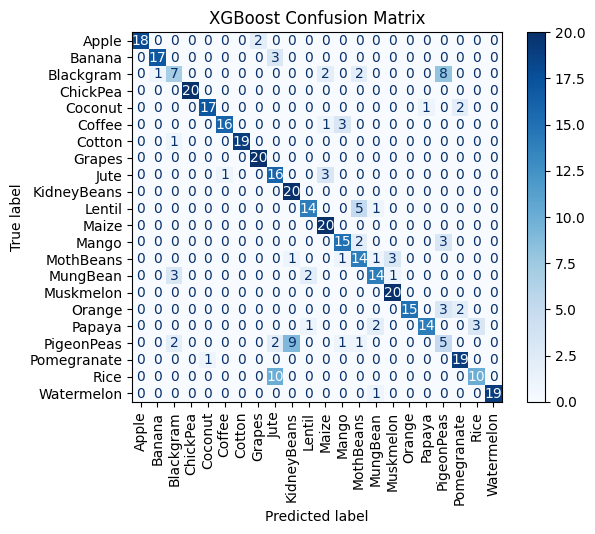

In [ ]:
plt.figure(figsize=(10, 8))
cm_xgb = confusion_matrix(y_test, y_pred_xgb_low)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=label_encoder.classes_)
disp_xgb.plot(cmap='Blues', xticks_rotation=90)
plt.title('XGBoost Confusion Matrix')
plt.show()

<Figure size 1000x800 with 0 Axes>

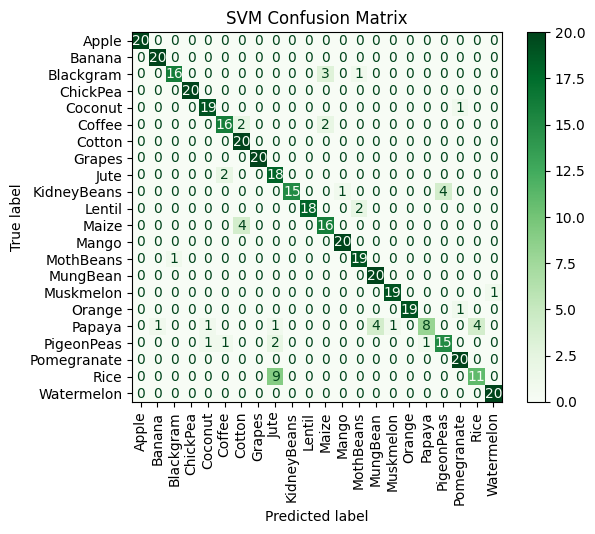

In [ ]:
plt.figure(figsize=(10, 8))
cm_svm = confusion_matrix(y_test, y_pred_svm_vlow)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=label_encoder.classes_)
disp_svm.plot(cmap='Greens', xticks_rotation=90)
plt.title('SVM Confusion Matrix')
plt.show()

In [ ]:
# Ensure we are working with the original X (before noise was added for degradation experiments)
X_fe = cr.drop(['Crop', 'Crop_encoded'], axis=1).copy()

# Calculate NPK Ratios
X_fe['N_to_P_Ratio'] = X_fe['Nitrogen'] / (X_fe['Phosphorus'] + 1e-6)  # Add small epsilon to avoid division by zero
X_fe['N_to_K_Ratio'] = X_fe['Nitrogen'] / (X_fe['Potassium'] + 1e-6)
X_fe['P_to_K_Ratio'] = X_fe['Phosphorus'] / (X_fe['Potassium'] + 1e-6)

# Display the new features and their statistics
print('Original features shape:', X.shape)
print('Features with NPK Ratios shape:', X_fe.shape)
display(X_fe.head())
display(X_fe[['N_to_P_Ratio', 'N_to_K_Ratio', 'P_to_K_Ratio']].describe())

Original features shape: (2200, 7)
Features with NPK Ratios shape: (2200, 10)


,Nitrogen,Phosphorus,Potassium,Temperature,Humidity,pH_Value,Rainfall,N_to_P_Ratio,N_to_K_Ratio,P_to_K_Ratio
0,90,42,43,20.879744,82.002744,6.502985,202.935536,2.142857,2.093023,0.976744
1,85,58,41,21.770462,80.319644,7.038096,226.655537,1.465517,2.073171,1.414634
2,60,55,44,23.004459,82.320763,7.840207,263.964248,1.090909,1.363636,1.250000
3,74,35,40,26.491096,80.158363,6.980401,242.864034,2.114286,1.850000,0.875000
4,78,42,42,20.130175,81.604873,7.628473,262.717340,1.857143,1.857143,1.000000


,N_to_P_Ratio,N_to_K_Ratio,P_to_K_Ratio
count,2200.000000,2200.000000,2200.000000
mean,1.701689,1.670538,1.668555
std,2.573334,1.507555,1.197217
min,0.000000,0.000000,0.090909
25%,0.350000,0.559706,0.697874
50%,0.890909,1.388322,1.262531
75%,1.977399,2.167453,2.588235
max,23.799995,9.333333,5.999999


In [ ]:
# Re-scale features using StandardScaler with new features
scaler_fe = StandardScaler()
X_fe_scaled = scaler_fe.fit_transform(X_fe)

# Re-split into training and testing sets with new features
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Shape of X_train (features with NPK ratios): {X_train_fe.shape}")
print(f"Shape of X_test (features with NPK ratios): {X_test_fe.shape}")

Shape of X_train (features with NPK ratios): (1760, 10)
Shape of X_test (features with NPK ratios): (440, 10)


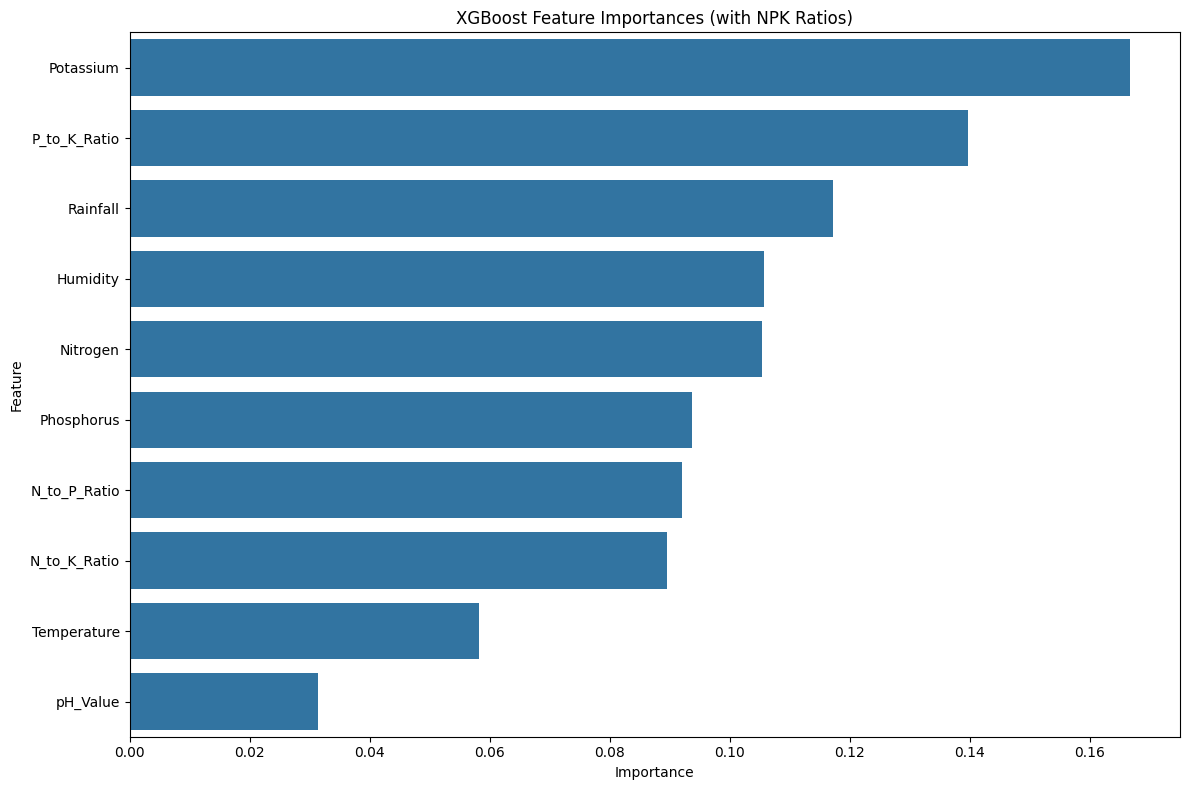

In [ ]:
import matplotlib.pyplot as plt

# Get feature importances from the best XGBoost model
feature_importances = best_xgb_model.feature_importances_

# Get feature names (original + new NPK ratios)
feature_names_fe = list(X_fe.columns)

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names_fe,
    'Importance': feature_importances
})

# Sort by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('XGBoost Feature Importances (with NPK Ratios)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()